# FashionMNIST CNN Depth Study

## Experimental Analysis

This notebook analyzes the results of a controlled experiment investigating how CNN depth and width affect image-classification performance on the FashionMNIST dataset.

Three architectures were evaluated:

- **CNN5** — baseline 5-convolution architecture
- **CNN5Wide** — wider 5-convolution architecture
- **CNN7** — deeper 7-convolution architecture

Each architecture was evaluated across five random seeds (42–46), resulting in 15 experimental runs.

The analysis focuses on:

- Validation accuracy
- Run-to-run variability
- Model parameter count
- Performance differences across random seeds
- Paired statistical comparisons

## Research Question

> How does increasing convolutional network depth or width affect classification performance on FashionMNIST under a controlled training configuration?

The experiment is designed to isolate architectural differences while keeping the general training configuration consistent across models.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import ttest_rel

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
with open("../results/raw_results.json", "r") as f:
    raw_results = json.load(f)

print(f"Number of experimental runs: {len(raw_results)}")

Number of experimental runs: 15


In [3]:
results = pd.DataFrame([
    {
        "model": run["model"],
        "seed": run["seed"],
        "parameters": run["parameters"],
        "best_epoch": run["best_epoch"],
        "best_val_loss": run["best_val_loss"],
        "best_val_accuracy": run["best_val_accuracy"],
        "epochs_completed": run["epochs_completed"]
    }
    for run in raw_results
])

results

,model,seed,parameters,best_epoch,best_val_loss,best_val_accuracy,epochs_completed
0,CNN5,42,2142474,5,0.198172,0.933000,10
1,CNN5,43,2142474,5,0.200625,0.933833,10
2,CNN5,44,2142474,5,0.200396,0.930167,10
3,CNN5,45,2142474,5,0.197907,0.934333,10
4,CNN5,46,2142474,5,0.198235,0.933167,10
5,CNN7,42,2326986,5,0.210946,0.926833,10
6,CNN7,43,2326986,6,0.214700,0.923167,11
7,CNN7,44,2326986,5,0.205499,0.927833,10
8,CNN7,45,2326986,5,0.208475,0.928667,10
9,CNN7,46,2326986,5,0.222338,0.921000,10


## Experimental Results

The experiment contains 15 runs in total:

- 5 runs for CNN5
- 5 runs for CNN5Wide
- 5 runs for CNN7

Each model uses the same set of random seeds, allowing paired comparisons between architectures.

In [4]:
summary = (
    results
    .groupby("model")
    .agg(
        parameters=("parameters", "first"),
        mean_val_accuracy=("best_val_accuracy", "mean"),
        std_val_accuracy=("best_val_accuracy", "std"),
        min_val_accuracy=("best_val_accuracy", "min"),
        max_val_accuracy=("best_val_accuracy", "max"),
        mean_best_epoch=("best_epoch", "mean")
    )
    .reset_index()
)

summary["mean_val_accuracy_percent"] = summary["mean_val_accuracy"] * 100
summary["std_val_accuracy_percent"] = summary["std_val_accuracy"] * 100

summary

,model,parameters,mean_val_accuracy,std_val_accuracy,min_val_accuracy,max_val_accuracy,mean_best_epoch,mean_val_accuracy_percent,std_val_accuracy_percent
0,CNN5,2142474,0.9329,0.001618,0.930167,0.934333,5.0,93.29,0.161847
1,CNN5Wide,2386954,0.9319,0.002200,0.928833,0.934000,4.8,93.19,0.220038
2,CNN7,2326986,0.9255,0.003277,0.921000,0.928667,5.2,92.55,0.327660


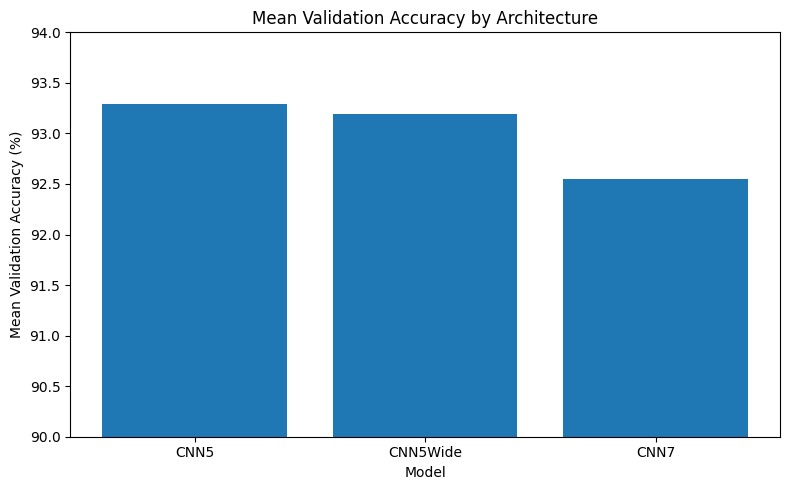

In [5]:
plt.figure(figsize=(8, 5))

plt.bar(
    summary["model"],
    summary["mean_val_accuracy_percent"]
)

plt.ylabel("Mean Validation Accuracy (%)")
plt.xlabel("Model")
plt.title("Mean Validation Accuracy by Architecture")
plt.ylim(90, 94)

plt.tight_layout()
plt.show()

## Mean Validation Accuracy

CNN5 achieved the highest mean validation accuracy at **93.29%**.

CNN5Wide achieved **93.19%**, while CNN7 achieved **92.55%**.

The results suggest that increasing model capacity through additional depth or width did not automatically improve validation performance under the experimental configuration used here.

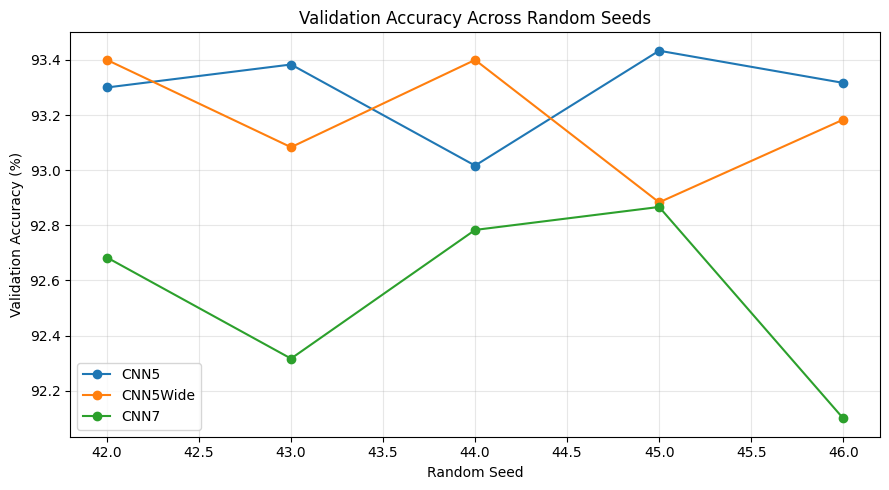

In [6]:
plt.figure(figsize=(9, 5))

for model in ["CNN5", "CNN5Wide", "CNN7"]:
    model_results = results[results["model"] == model]

    plt.plot(
        model_results["seed"],
        model_results["best_val_accuracy"] * 100,
        marker="o",
        label=model
    )

plt.xlabel("Random Seed")
plt.ylabel("Validation Accuracy (%)")
plt.title("Validation Accuracy Across Random Seeds")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Run-to-Run Variability

CNN5 showed the lowest standard deviation across the five random seeds:

- CNN5: **0.162 percentage points**
- CNN5Wide: **0.220 percentage points**
- CNN7: **0.328 percentage points**

This indicates that CNN5 produced the most consistent validation performance among the three architectures in this experiment.

In [7]:
seed_order = [42, 43, 44, 45, 46]

pivot = results.pivot(
    index="seed",
    columns="model",
    values="best_val_accuracy"
).loc[seed_order]

pivot

model,CNN5,CNN5Wide,CNN7
seed,,,
42,0.933000,0.934000,0.926833
43,0.933833,0.930833,0.923167
44,0.930167,0.934000,0.927833
45,0.934333,0.928833,0.928667
46,0.933167,0.931833,0.921000


In [8]:
cnn5_vs_cnn7 = ttest_rel(
    pivot["CNN5"],
    pivot["CNN7"]
)

print("CNN5 vs CNN7")
print(f"t-statistic: {cnn5_vs_cnn7.statistic:.4f}")
print(f"p-value: {cnn5_vs_cnn7.pvalue:.4f}")
print(f"degrees of freedom: {cnn5_vs_cnn7.df}")

CNN5 vs CNN7
t-statistic: 4.1501
p-value: 0.0143
degrees of freedom: 4


In [9]:
cnn5_vs_wide = ttest_rel(
    pivot["CNN5"],
    pivot["CNN5Wide"]
)

print("CNN5 vs CNN5Wide")
print(f"t-statistic: {cnn5_vs_wide.statistic:.4f}")
print(f"p-value: {cnn5_vs_wide.pvalue:.4f}")
print(f"degrees of freedom: {cnn5_vs_wide.df}")

CNN5 vs CNN5Wide
t-statistic: 0.6218
p-value: 0.5677
degrees of freedom: 4


## Statistical Interpretation

A paired t-test was used because the same random seeds were evaluated for each architecture.

### CNN5 vs CNN7

The paired test produced:

- **t = 4.1501**
- **p = 0.0143**

Since p < 0.05, the difference is statistically significant at the conventional 5% significance level.

CNN5 therefore showed significantly higher validation accuracy than CNN7 under the controlled experimental configuration.

### CNN5 vs CNN5Wide

The paired test produced:

- **t = 0.6218**
- **p = 0.5677**

Since p > 0.05, there is insufficient evidence to conclude that CNN5 and CNN5Wide have different validation performance.

Although CNN5 had a slightly higher mean accuracy, the observed difference may reasonably be explained by run-to-run variation.

In [10]:
cnn5_cnn7_diff = (
    pivot["CNN5"] - pivot["CNN7"]
) * 100

cnn5_wide_diff = (
    pivot["CNN5"] - pivot["CNN5Wide"]
) * 100

print("CNN5 - CNN7 differences (percentage points):")
print(cnn5_cnn7_diff.round(3).tolist())

print("\nCNN5 - CNN5Wide differences (percentage points):")
print(cnn5_wide_diff.round(3).tolist())

CNN5 - CNN7 differences (percentage points):
[0.617, 1.067, 0.233, 0.567, 1.217]

CNN5 - CNN5Wide differences (percentage points):
[-0.1, 0.3, -0.383, 0.55, 0.133]


## Conclusion

Under the controlled training configuration used in this experiment, CNN5 achieved the highest mean validation accuracy and the lowest run-to-run variability.

Increasing depth from five to seven convolutional layers resulted in lower validation performance, and the difference was statistically significant across the five matched random seeds.

In contrast, increasing the width of the five-layer network did not produce a statistically significant improvement despite increasing the number of parameters.

These findings suggest that increasing model capacity does not necessarily improve generalization. Architectural changes should therefore be evaluated experimentally rather than assuming that deeper or larger models will always perform better.

The conclusions are specific to this dataset, architecture design, and training configuration and should not be interpreted as a universal statement about CNN depth.